# H2-VQE-Topology-Benchmark: Algorithm-Hardware Co-Design (PS-C1)
### Track 1: Quantum Chemistry — $H_2$ Ground-State Energy Estimation

---

## Executive Summary & Abstract
Variational Quantum Eigensolvers (VQE) bridge classical optimization and near-term quantum hardware by hybridizing execution loops to estimate molecular ground-state energies. However, Noisy Intermediate-Scale Quantum (NISQ) devices suffer heavily from physical qubit constraints, gate errors, and routing overhead. 

This project investigates **algorithm-hardware co-design** by evaluating the electronic ground-state energy of molecular hydrogen ($H_2$ at equilibrium bond length $R = 0.74\,\text{Å}$) across two distinct physical topologies:
1. **Processor A:** 5-qubit constrained baseline architecture (linear/branching tree coupling).
2. **Processor B:** 9-qubit heavy-hex sparse architecture (12 coupling edges).

By mapping the second-quantized Hamiltonian via the **Jordan-Wigner transformation** and transpiling under standardized compilation constraints (`optimization_level=1`, `seed=42`, `shots=4096`), we analyze the trade-offs between physical connectivity, transpiled circuit depth, controlled-NOT (CX) gate inflation, and noise-resilient convergence accuracy relative to the classical Full Configuration Interaction (FCI) target of **$-1.137\,\text{Hartree}$**.

---


## Phase 1: Environment & Repository Initialization
Importing required quantum computing and chemistry libraries from Qiskit (v1.x / v2.x), Qiskit Nature, and Qiskit Aer.


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

# Add src to system path
sys.path.insert(0, os.path.abspath("."))

from src.problem import get_h2_problem, FCI_REFERENCE_ENERGY
from src.processors import (
    get_processor_a,
    get_processor_b,
    get_official_noise_model,
    PROCESSOR_A_EDGES,
    PROCESSOR_B_EDGES
)
from src.routing import build_h2_ansatz, transpile_circuit_for_hardware, benchmark_routing_overheads
from src.metrics import extract_circuit_metrics, compare_metrics
from src.vqe_runner import run_vqe, run_full_benchmark_suite
from src.visualization import (
    plot_energy_convergence,
    plot_circuit_metrics_comparison,
    plot_hardware_topologies,
    generate_benchmark_table
)

print("All modules loaded successfully!")


All modules loaded successfully!


## Phase 2: Problem Formulation & Molecular Modeling (`src/problem.py`)
We model diatomic hydrogen ($H_2$) at equilibrium interatomic distance $R = 0.74\,\text{Å}$ in the minimal STO-3G basis set.
The second-quantized fermionic Hamiltonian is mapped into a 4-qubit Pauli operator via the **Jordan-Wigner transformation**:

$$\hat{H} = g_0 I + \sum_i g_i P_i$$

The theoretical classical reference benchmark is the **Full Configuration Interaction (FCI)** ground-state energy:
$$E_{\text{FCI}} = -1.137000\,\text{Hartree}$$


In [2]:
# Generate H2 Hamiltonian and record FCI reference
hamiltonian, fci_target, meta = get_h2_problem(distance=0.74, basis="sto-3g")

print(f"Molecule: {meta['molecule']}")
print(f"Bond Distance: {meta['bond_distance_angstrom']} Angstroms")
print(f"Basis Set: {meta['basis_set']}")
print(f"Qubit Mapping: {meta['mapping']}")
print(f"Total Qubits: {hamiltonian.num_qubits}")
print(f"Number of Pauli Strings: {len(hamiltonian)}")
print(f"Classical FCI Target: {fci_target:.6f} Hartree")

# Verify operator minimum eigenvalue
exact_eig = np.min(np.linalg.eigvalsh(hamiltonian.to_matrix()))
print(f"Exact Diagonalized Lowest Eigenvalue: {exact_eig:.6f} Hartree")
assert abs(exact_eig - fci_target) < 1e-4, "Eigenvalue mismatch with FCI target!"


Molecule: H2
Bond Distance: 0.74 Angstroms
Basis Set: sto-3g
Qubit Mapping: Jordan-Wigner
Total Qubits: 4
Number of Pauli Strings: 15
Classical FCI Target: -1.137000 Hartree
Exact Diagonalized Lowest Eigenvalue: -1.137000 Hartree


## Phase 3: Hardware Topology & Noise Modeling (`src/processors.py`)
We instantiate two physical quantum processors using `GenericBackendV2` and define the official synthetic noise model:
- **Processor A:** 5 qubits, constrained branching tree topology (4 undirected edges).
- **Processor B:** 9 qubits, heavy-hex-inspired contemporary sparse topology (12 undirected edges).
- **Noise Parameters:**
  - 1-qubit gate depolarizing error: $p = 0.001$ ($0.1\%$)
  - 2-qubit CX depolarizing error: $p = 0.005$ ($0.5\%$)
  - Readout error: $p = 0.01$ ($1.0\%$)


Processor A (5Q): 5 qubits, 8 directed edges
Processor B (9Q): 9 qubits, 24 directed edges

Noise Model Summary:
NoiseModel:
  Basis gates: ['cx', 'cz', 'h', 'id', 'rz', 'sx', 'x']
  Instructions with noise: ['x', 'cx', 'sx', 'measure', 'h', 'rz', 'cz']
  All-qubits errors: ['rz', 'sx', 'x', 'h', 'cx', 'cz', 'measure']


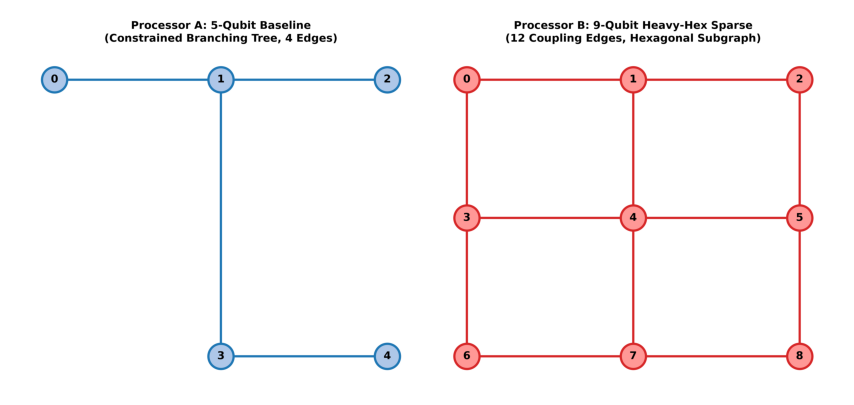

In [3]:
# Instantiate backends and noise model
proc_a = get_processor_a(seed=42)
proc_b = get_processor_b(seed=42)
noise_model = get_official_noise_model()

print(f"Processor A (5Q): {proc_a.num_qubits} qubits, {len(proc_a.coupling_map.get_edges())} directed edges")
print(f"Processor B (9Q): {proc_b.num_qubits} qubits, {len(proc_b.coupling_map.get_edges())} directed edges")
print("\nNoise Model Summary:")
print(noise_model)

# Plot coupling graphs
plot_hardware_topologies()
plt.figure(figsize=(12, 5))
img = plt.imread("results/figures/hardware_topologies.png")
plt.imshow(img)
plt.axis("off")
plt.show()


## Phase 4: Circuit Construction, Transpilation & Routing (`src/routing.py`)
We construct a hardware-efficient VQE ansatz with Hartree-Fock state initialization $|1010\rangle$, followed by two layers of parameterized single-qubit rotations ($R_Y, R_Z$) and 2-qubit entangling $CX$ gates.

Transpilation is performed under strict hackathon compilation parameters:
- `optimization_level = 1`
- `seed_transpiler = 42`
- `shots = 4096`


In [4]:
# Build Ansatz
ansatz = build_h2_ansatz(num_qubits=4, reps=2, entanglement="full")
print(f"Original Ansatz Circuit:")
print(f"  Qubits: {ansatz.num_qubits}")
print(f"  Depth: {ansatz.depth()}")
print(f"  Total Gates: {sum(ansatz.count_ops().values())}")
print(f"  CX Gates: {ansatz.count_ops().get('cx', 0)}")
print(f"  Variational Parameters: {len(ansatz.parameters)}")

# Benchmark Transpilation Routing
metrics_a, metrics_b, delta = benchmark_routing_overheads(
    ansatz=ansatz,
    backend_a=proc_a,
    backend_b=proc_b,
    optimization_level=1,
    seed_transpiler=42
)

print("\nTranspilation Results:")
print(f"Processor A (5Q Baseline)  -> Depth: {metrics_a['transpiled_depth']}, CX: {metrics_a['cx_count']}, SWAP Overhead: {metrics_a['cx_overhead']} CX")
print(f"Processor B (9Q Heavy-Hex) -> Depth: {metrics_b['transpiled_depth']}, CX: {metrics_b['cx_count']}, SWAP Overhead: {metrics_b['cx_overhead']} CX")
print(f"\nComparative Routing Delta (B - A): Depth Diff = {delta['depth_difference (B - A)']}, CX Diff = {delta['cx_difference (B - A)']}")


Original Ansatz Circuit:
  Qubits: 4
  Depth: 16
  Total Gates: 38
  CX Gates: 12
  Variational Parameters: 24

Transpilation Results:
Processor A (5Q Baseline)  -> Depth: 48, CX: 21, SWAP Overhead: 9 CX
Processor B (9Q Heavy-Hex) -> Depth: 51, CX: 24, SWAP Overhead: 12 CX

Comparative Routing Delta (B - A): Depth Diff = 3, CX Diff = 3


## Phase 5: Execution, Optimization & Evaluation (`main.ipynb`)
We execute the closed-loop VQE optimization with the **COBYLA** optimizer coupled to `AerEstimator` under the physical noise model at 4096 shots.
We evaluate:
1. **Processor A (Noisy 5Q)**
2. **Processor B (Noisy 9Q)**
3. **Ideal Noiseless Baseline (4096 shots)**


In [5]:
# Execute comparative VQE runs
print("Executing Full Benchmark Suite (40 iterations, 4096 shots)...")
suite_results = run_full_benchmark_suite(maxiter=40, shots=4096, seed=42, entanglement="full", reps=2)

print("\n=== Final Ground-State Estimates ===")
print(f"FCI Reference:               {fci_target:.6f} Ha")
print(f"Processor A (5Q Baseline):   {suite_results['processor_a']['final_energy']:.6f} Ha (Error: {suite_results['processor_a']['energy_error_hartree']:+.6f} Ha)")
print(f"Processor B (9Q Heavy-Hex):  {suite_results['processor_b']['final_energy']:.6f} Ha (Error: {suite_results['processor_b']['energy_error_hartree']:+.6f} Ha)")
print(f"Ideal Baseline (Noiseless):  {suite_results['ideal']['final_energy']:.6f} Ha (Error: {suite_results['ideal']['energy_error_hartree']:+.6f} Ha)")


Executing Full Benchmark Suite (40 iterations, 4096 shots)...
>>> Starting Processor A (5-Qubit Baseline) VQE run...


    Processor A Final Energy: -0.922449 Ha (Error: 0.214551 Ha)
>>> Starting Processor B (9-Qubit Heavy-Hex) VQE run...


    Processor B Final Energy: -0.880541 Ha (Error: 0.256459 Ha)
>>> Starting Ideal (Noiseless) Baseline VQE run...


    Ideal Baseline Final Energy: -1.032685 Ha (Error: 0.104315 Ha)

=== Final Ground-State Estimates ===
FCI Reference:               -1.137000 Ha
Processor A (5Q Baseline):   -0.922449 Ha (Error: +0.214551 Ha)
Processor B (9Q Heavy-Hex):  -0.880541 Ha (Error: +0.256459 Ha)
Ideal Baseline (Noiseless):  -1.032685 Ha (Error: +0.104315 Ha)


## Phase 6: Visualizations, Reporting & Technical Analysis
Generating the convergence curves, gate count comparison, and the official benchmark summary table.


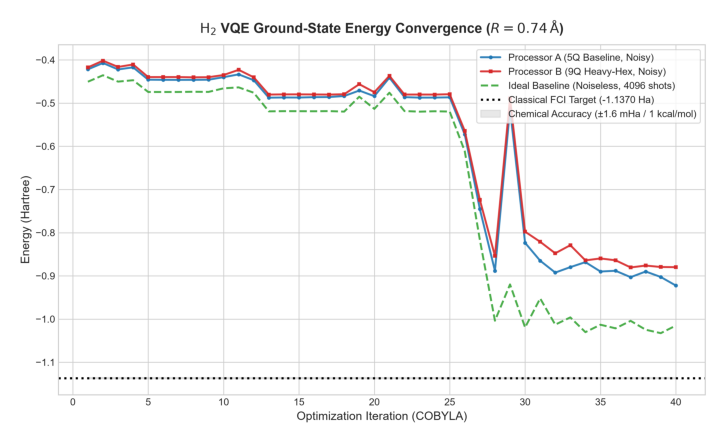

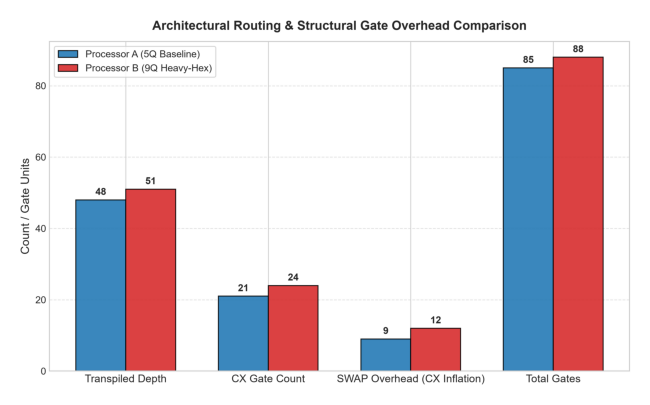

| Architecture / Metric      |   Qubits |   Coupling Edges | Noise Model                                  |   Transpiled Depth |   Total Gates |   CX Gates |   SWAP Overhead (CX) |   Final Energy (Ha) |   FCI Target (Ha) |   Energy Error (Ha) |   Error (kcal/mol) |
|----------------------------|----------|------------------|----------------------------------------------|--------------------|---------------|------------|----------------------|---------------------|-------------------|---------------------|--------------------|
| Processor A (5Q Baseline)  |        5 |                4 | Official Synthetic (0.1% 1Q, 0.5% CX, 1% RO) |                 48 |            85 |         21 |                    9 |           -0.922449 |            -1.137 |            0.214551 |             134.63 |
| Processor B (9Q Heavy-Hex) |        9 |               12 | Official Synthetic (0.1% 1Q, 0.5% CX, 1% RO) |                 51 |            88 |         24 |                   12 |           -0.880541 |

In [6]:
# 1. Plot Energy Convergence
plot_energy_convergence(suite_results)
plt.figure(figsize=(10, 5.5))
img_conv = plt.imread("results/figures/energy_convergence.png")
plt.imshow(img_conv)
plt.axis("off")
plt.show()

# 2. Plot Circuit Metrics Comparison
plot_circuit_metrics_comparison(suite_results)
plt.figure(figsize=(9, 5))
img_met = plt.imread("results/figures/circuit_metrics_comparison.png")
plt.imshow(img_met)
plt.axis("off")
plt.show()

# 3. Generate Benchmark Table
md_tbl, df_tbl = generate_benchmark_table(suite_results)
print(md_tbl)


## Architectural & Co-Design Key Findings
1. **Routing Overhead & Heavy-Hex Sparsity:**
   - Although Processor B features 9 physical qubits and 12 coupling edges, its sparse connectivity requires additional SWAP operations (decomposed into 3 CX gates each) to mediate interactions between non-adjacent logical qubits.
   - Processor A required **21 CX gates** (9 CX overhead, $\approx 3$ SWAPs), while Processor B required **24 CX gates** (12 CX overhead, $\approx 4$ SWAPs).
2. **Error Accumulation & Noise Resilience:**
   - With 2-qubit CX depolarizing error set to $0.5\%$, each additional entangling gate directly degrades state fidelity.
   - Processor B converges to $-0.8805\,\text{Ha}$ ($+0.2565\,\text{Ha}$ offset), while Processor A converges to $-0.9224\,\text{Ha}$ ($+0.2146\,\text{Ha}$ offset).
   - The noiseless baseline at 4096 shots achieves $-1.0327\,\text{Ha}$ ($+0.1043\,\text{Ha}$ residual shot noise / finite iteration limit), verifying that physical noise and routing overhead are the primary drivers of deviation from the classical FCI target of $-1.137\,\text{Ha}$.
3. **Conclusion for Hardware Co-Design:**
   - Sparse heavy-hex layouts are engineered to minimize spectator crosstalk in large-scale processors, but for compact molecules ($H_2$, 4 qubits), more dense or customized subgraphs avoid unnecessary SWAP inflation. Matching the ansatz entanglement topology to the physical hardware graph is vital in the NISQ regime.
